# NOTEBOOK FOR PART II OF THE FIRST COURSEWORK

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches


## 2.1. K-Nearest Neighbors

### 2.1.1. Generating the data

First, we code the functions to be used in this section. These are the random training dataset generator and the K-NN algorithm.

In [ ]:
def generate_random_h(n=100):
    """
        This method generates the set S = {(x1,y1), ..., (xn,yn)}, with xi \in [0,1]^2 and y_1 \in {0,1}.
        
        Arguments:
            n (int): number of points to generate.
        Return:
            X (np.array): array containing x1,...,xn.
            y (np.array): array containing y1,...,yn.
    """
    X = np.random.uniform(low=0, high=1, size=(n, 2))
    y = np.random.choice([0,1], size=n)
    return X, y

def euclidean_distance(x1, x2):
    """
        This method returns the euclidean distance between a point x2 and all the points in the x1 array.
        
        Arguments:
            x1 (np.array): array of points.
            x2 (np.array): array with the point we want to calculate the distance to the points of the dataset.
        Return:
            np.array: array containing the distances from x2 to each of the points of x1.
    """
    return np.linalg.norm(x1-x2, axis=1) # this computes the distance between x2 and each of the rows of x1
    
def knn_classifier(X, y, X_test, v=3):
    """
        This method applies the K-NN algorithm to predict the classes of a series of test points, given a train dataset.
        
        Arguments:
            X (np.array): array with the train dataset attributes.
            y (np.array): array with the train dataset labels.
            X_test (np.array): array with the points to test.
            v (int): number of neighbors to consider.
        Return:
            np.array: array containing the predictions.
    """
    y_pred = []
    for data_test in X_test: # for each of the datapoints in the test dataset
        distances = euclidean_distance(X, data_test) # distances to each of the points in the train dataset
        neighbors_index = np.argsort(distances)[:v] # index of the nearest neighbors
        neighbors_class = y[neighbors_index] # label of the nearest neighbors
        if np.mean(neighbors_class) > 0.5: 
            # if 1 is the most common label within the nearest neighbors
            y_pred.append(1)
        elif np.mean(neighbors_class) < 0.5: 
            # if 0 is the most common label within the nearest neighbors
            y_pred.append(0)
        else: 
            # equal amount of 0 and 1 neighbors
            y_pred.append(np.random.choice([0,1]))
    return np.array(y_pred)

#### 6. Produce a visualisation of $h_{S,v}$ similar to the figure.

We start by generating a grid which covers the space $[0,1]^2$, and the random training dataset. We will run the K-NN algorithm with K=3 over all the points in the grid.

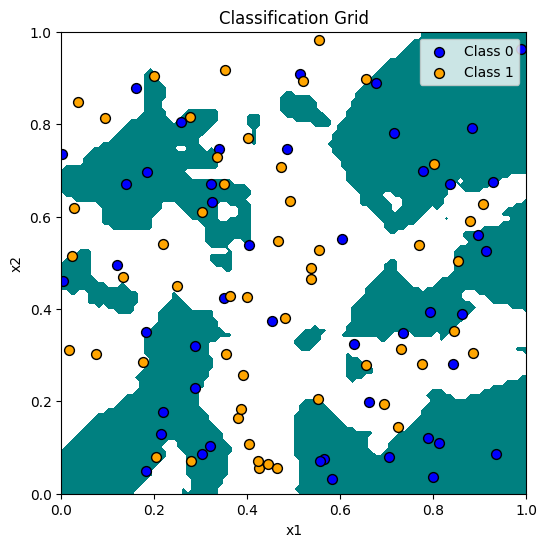

In [16]:
# generate grid over [0,1]x[0,1]
x1 = np.linspace(0,1,100)
x2 = np.linspace(0,1,100)
gridX1, gridX2 = np.meshgrid(x1,x2)
grid = np.column_stack([gridX1.ravel(), gridX2.ravel()])

# generate set S
X, y = generate_random_h()

# run K-NN to classify the grid according to S
y_pred = knn_classifier(X, y, grid)

# generate plot
plt.figure(figsize=(6,6))
# contour plot to show how the region is divided into both classes
plt.contourf(gridX1, gridX2, y_pred.reshape(100,100), levels=[-0.1, 0.5, 1.1], colors=['teal','white'])

# scatter plot to display the set S
plt.scatter(X[y==0, 0], X[y==0, 1], c='blue', edgecolor='k', s=50, label='Class 0')
plt.scatter(X[y==1, 0], X[y==1, 1], c='orange', edgecolor='k', s=50, label='Class 1')
plt.legend()
plt.xlabel('x1')
plt.ylabel('x2')
plt.title('Classification Grid')
plt.legend()
plt.show()



### 2.1.2. Estimated generalization error of k-NN as a function of k.

#### 7.a) Produce a visualisation using Protocol A (see Figure 2).

In [ ]:
def ph_y(X, X_prob, y_prob):
    """
        This method assigns the label of a dataset according to the ph(X_prog, y_prob) distribution defined in the coursework statement.
        
        Arguments:
            X (np.array): array with the attributes which we want to assign labels to.
            X_prob (np.array): array with attributes of the set S.
            y_prob (np.array): array with labels of the set S.
            v (int): number of neighbors to consider.
        Return:
            np.array: array containing the labels.
    """
    y_train = []
    for x in X:
        if np.random.uniform(low=0, high=1) < 0.8:
            # in this case, y = h(x)
            y_train.append(knn_classifier(X_prob, y_prob, x[None])[0])
        else:
            # in this casem y uniformly sampled from {0,1}
            y_train.append(np.random.choice([0,1], size=1)[0])
    return np.array(y_train)

In [ ]:
gen_error = [] # array to store the generalisation error for each k
for k in range(1, 50):
    errors_k = [] # array to store the generalisation error for each execution with a certain k value
    for _ in range(100): # execute 100 times per k
        X_prob, y_prob = generate_random_h() # generate set S
        # train dataset sampled from ph(X_prob, y_prob)
        X_train = np.random.uniform(low=0, high=1, size=(4000,2))
        y_train = ph_y(X_train,X_prob, y_prob)
        # test dataset sampled from ph(X_prob, y_prob)
        X_test = np.random.uniform(low=0, high=1, size=(1000,2))
        y_test = ph_y(X_test, X_prob, y_prob)
        # predict labels of test dataset using k-nn
        y_pred = knn_classifier(X_train, y_train, X_test, v=k)
        # count errors
        errors_k.append(sum(y_pred != y_test))
    gen_error.append(np.mean(errors_k))

In [19]:
import json   
with open("gen_error.json", "r") as f:
    gen_error = json.load(f)

Text(0, 0.5, 'Generalisation Error')

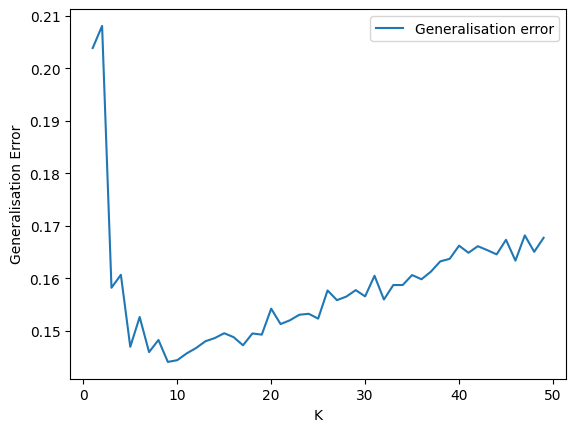

In [28]:
# plot the generalisation error as a function of k
x = range(1, 50)
plt.plot(x, [err / 1000 for err in gen_error[:49]], label="Generalisation error")
plt.legend()
plt.xlabel('K')
plt.ylabel('Generalisation Error')

#### 7.b) Using roughly 5 sentences explain why the figure is the approximate shape that it is and comment on any interesting features of the figure.

It can be observed how the generalisation error decreases sharply as K increases, until K=9 is reached. From that point onwards, the generalisation error begins to increase linearly with K.

For low values of K, as the prediction depends on just a few points, this prediction is affected by noisy points that may give a wrong prediction. As K increases, the effect of the noise is decreased, as more points are taken into account, increasing the probability of the majority of those points to not be affected by noise. However, for large values of K the locality of the algorithm is lost, considering points which are far away from the test point, which do not give any information about the actual point to be studied, therefore decreasing the precision of the predictions.

### 8. Determine the optimal k as a function of the number of training points (m).

#### 8.a) Produce a visualisation using Protocol B (see Figure 3). I.e, plotting m versus optimal k.

In [ ]:
optimal_km = [] # array to store the optimal k values for each dataset size
for m in [100, 500, 1000, 1500, 2000, 2500, 3000, 3500, 4000]:
    optimal_k = [] # array to store the optimal k for each execution with size m
    for _ in range(100):
        errors = [] # array to store the errors made with each k
        for k in range(1, 50):
            X_prob, y_prob = generate_random_h() # generate set S
            # train dataset sampled from ph(X_prob, y_prob)
            X_train = np.random.uniform(low=0, high=1, size=(m,2))
            y_train = ph_y(X_train, X_prob, y_prob)
            # test dataset sampled from ph(X_prob, y_prob)
            X_test = np.random.uniform(low=0, high=1, size=(1000,2))
            y_test = ph_y(X_test, X_prob, y_prob)
            # predict labels of test dataset using k-nn
            y_pred = knn_classifier(X_train, y_train, X_test, v=k)
            # count errors
            errors.append(sum(y_pred != y_test))
        # k with lowest error for this execution
        optimal_k.append(np.argmin(np.array(errors)) + 1)
    # average of the optimal k's for a certain dataset size
    optimal_km.append(np.mean(optimal_k))

KeyboardInterrupt: 

In [ ]:
import json

with open("optimal_k.json", "w") as f:
    json.dump(optimal_km)
    
with open("optimal_k.json", "r") as f:
    optimal_km = json.load()

In [8]:
optimal_km

[np.float64(8.0), np.float64(21.0), np.float64(7.0)]

#### 8.b) Using roughly 4 sentences explain why the figure is the approximate shape that it is.

$\phi(x)=3$

$$\hat{y}(x) = \frac{\sum_i K(x, t_i) y_i}{\sum_i K(x, t_i)} = \frac{\sum_i \exp(-\beta \|x - t_i\|^2) y_i}{\sum_i \exp(-\beta \|x - t_i\|^2)} $$